# Dataset Exploration

Initial research of the MovieLens 100K dataset 

In [2]:
from pathlib import Path

data_directory = Path("../data/ml-100k")

list(data_directory.iterdir())

[WindowsPath('../data/ml-100k/allbut.pl'),
 WindowsPath('../data/ml-100k/mku.sh'),
 WindowsPath('../data/ml-100k/README'),
 WindowsPath('../data/ml-100k/u.data'),
 WindowsPath('../data/ml-100k/u.genre'),
 WindowsPath('../data/ml-100k/u.info'),
 WindowsPath('../data/ml-100k/u.item'),
 WindowsPath('../data/ml-100k/u.occupation'),
 WindowsPath('../data/ml-100k/u.user'),
 WindowsPath('../data/ml-100k/u1.base'),
 WindowsPath('../data/ml-100k/u1.test'),
 WindowsPath('../data/ml-100k/u2.base'),
 WindowsPath('../data/ml-100k/u2.test'),
 WindowsPath('../data/ml-100k/u3.base'),
 WindowsPath('../data/ml-100k/u3.test'),
 WindowsPath('../data/ml-100k/u4.base'),
 WindowsPath('../data/ml-100k/u4.test'),
 WindowsPath('../data/ml-100k/u5.base'),
 WindowsPath('../data/ml-100k/u5.test'),
 WindowsPath('../data/ml-100k/ua.base'),
 WindowsPath('../data/ml-100k/ua.test'),
 WindowsPath('../data/ml-100k/ub.base'),
 WindowsPath('../data/ml-100k/ub.test')]

## Dataset documentation

Readme of the dataset

In [3]:
readme = (data_directory / "README").read_text()

print(readme)

SUMMARY & USAGE LICENSE

MovieLens data sets were collected by the GroupLens Research Project
at the University of Minnesota.
 
This data set consists of:
	* 100,000 ratings (1-5) from 943 users on 1682 movies. 
	* Each user has rated at least 20 movies. 
        * Simple demographic info for the users (age, gender, occupation, zip)

The data was collected through the MovieLens web site
(movielens.umn.edu) during the seven-month period from September 19th, 
1997 through April 22nd, 1998. This data has been cleaned up - users
who had less than 20 ratings or did not have complete demographic
information were removed from this data set. Detailed descriptions of
the data file can be found at the end of this file.

Neither the University of Minnesota nor any of the researchers
involved can guarantee the correctness of the data, its suitability
for any particular purpose, or the validity of results based on the
use of the data set.  The data set may be used for any research
purposes under th

## Ratings data

Load the 100,000 user-movie ratings from u.data 

In [4]:
import pandas as pd

ratings = pd.read_csv(
    data_directory / "u.data",
    sep="\t",
    names=["user_id", "movie_id", "rating", "timestamp"]
)

ratings.head()

,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [5]:
ratings.shape

(100000, 4)

## Checking the dataset

Check the size, data types, missing values and basic statistics of the ratings data.

In [6]:
print("data rows and columns:", ratings.shape)
print("types of data:")
print(ratings.dtypes)

data rows and columns: (100000, 4)
types of data:
user_id      int64
movie_id     int64
rating       int64
timestamp    int64
dtype: object


In [7]:
#check if there are missing values
ratings.isnull().sum()

user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

In [8]:

ratings.describe()

,user_id,movie_id,rating,timestamp
count,100000.00000,100000.000000,100000.000000,1.000000e+05
mean,462.48475,425.530130,3.529860,8.835289e+08
std,266.61442,330.798356,1.125674,5.343856e+06
min,1.00000,1.000000,1.000000,8.747247e+08
25%,254.00000,175.000000,3.000000,8.794487e+08
50%,447.00000,322.000000,4.000000,8.828269e+08
75%,682.00000,631.000000,4.000000,8.882600e+08
max,943.00000,1682.000000,5.000000,8.932866e+08


In [9]:
#check how the data are distributed
ratings["rating"].value_counts().sort_index()

rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64

## User data

Checking each users information.

In [10]:
users = pd.read_csv(
    data_directory/ "u.user",
    sep="|",
    names=["user_id", "age", "gender", "occupation", "zip_code"]
)

users.head()

,user_id,age,gender,occupation,zip_code
0,1,24,M,technician,85711
1,2,53,F,other,94043
2,3,23,M,writer,32067
3,4,24,M,technician,43537
4,5,33,F,other,15213


In [11]:
print("rows and columns of users:", users.shape)
#Print missing values
print("\nMissing values:")
print(users.isnull().sum())

rows and columns of users: (943, 5)

Missing values:
user_id       0
age           0
gender        0
occupation    0
zip_code      0
dtype: int64


## Movie Data

Check movie information.

In [12]:

genre_names = [
    "unknown", "Action", "Adventure", "Animation", "Children's",
    "Comedy", "Crime", "Documentary", "Drama", "Fantasy",
    "Film-Noir", "Horror", "Musical", "Mystery", "Romance",
    "Sci-Fi", "Thriller", "War", "Western"
]

movie_cols = [
    "movie_id",
    "title",
    "release_date",
    "video_release_date",
    "imdb_url",
    *genre_names
]

movies = pd.read_csv(
    data_directory / "u.item",
    sep="|",
    names=movie_cols,
    encoding="latin-1"
)

movies.head()

,movie_id,title,release_date,video_release_date,imdb_url,unknown,Action,Adventure,Animation,Children's,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,2,GoldenEye (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?GoldenEye%20(...,0,1,1,0,0,...,0,0,0,0,0,0,0,1,0,0
2,3,Four Rooms (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Four%20Rooms%...,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,4,Get Shorty (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Get%20Shorty%...,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,Copycat (1995),01-Jan-1995,NaN,http://us.imdb.com/M/title-exact?Copycat%20(1995),0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [13]:
print("rows and columns of movies:", movies.shape)
print("missing values:")
print(movies.isnull().sum())
print("\nGenre counts:")

rows and columns of movies: (1682, 24)
missing values:
movie_id                 0
title                    0
release_date             1
video_release_date    1682
imdb_url                 3
unknown                  0
Action                   0
Adventure                0
Animation                0
Children's               0
Comedy                   0
Crime                    0
Documentary              0
Drama                    0
Fantasy                  0
Film-Noir                0
Horror                   0
Musical                  0
Mystery                  0
Romance                  0
Sci-Fi                   0
Thriller                 0
War                      0
Western                  0
dtype: int64

Genre counts:


## Combined dataset

Merge ratings with user and movie info to make one row per user-movie rating.

In [14]:
data = (
    ratings
    .merge(users, on="user_id", how="left")
    .merge(movies, on="movie_id", how="left")
)

data.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,release_date,...,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,196,242,3,881250949,49,M,writer,55105,Kolya (1996),24-Jan-1997,...,0,0,0,0,0,0,0,0,0,0
1,186,302,3,891717742,39,F,executive,00000,L.A. Confidential (1997),01-Jan-1997,...,0,1,0,0,1,0,0,1,0,0
2,22,377,1,878887116,25,M,writer,40206,Heavyweights (1994),01-Jan-1994,...,0,0,0,0,0,0,0,0,0,0
3,244,51,2,880606923,28,M,technician,80525,Legends of the Fall (1994),01-Jan-1994,...,0,0,0,0,0,1,0,0,1,1
4,166,346,1,886397596,47,M,educator,55113,Jackie Brown (1997),01-Jan-1997,...,0,0,0,0,0,0,0,0,0,0


## Verifying 
Checking that nothing went wrong during the merge

In [15]:
print("Shape:", data.shape)

print("Unique users:", data["user_id"].nunique())
print("Unique movies:", data["movie_id"].nunique())

print("\nMissing info about users:")
print(data[["age", "gender", "occupation", "zip_code"]].isnull().sum())

print("\nMissing info about genre values:")
print(data[genre_names].isnull().sum().sum())

Shape: (100000, 31)
Unique users: 943
Unique movies: 1682

Missing info about users:
age           0
gender        0
occupation    0
zip_code      0
dtype: int64

Missing info about genre values:
0


### data validation

The ratings, user and movie datasets were merged into one dataset containing 100,000 ratings, 943 unique users, and 1,682 unique movies. Nothing was lost during the merge. The new dataset has 31 columns.

# Analazing data

## Rating distribution

Check how the 100,000 ratings are distributed across the 1–5 rating scale.

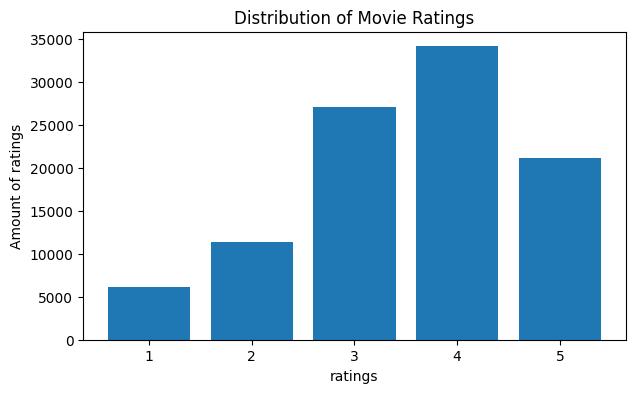

In [16]:
import matplotlib.pyplot as plt

rating_cnt = ratings["rating"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(rating_cnt.index, rating_cnt.values)
plt.xlabel("ratings")
plt.ylabel("Amount of ratings")
plt.title("Distribution of Movie Ratings")
plt.xticks([1, 2, 3, 4, 5])
plt.show()

## User activity

Check how many ratings each user has made.

In [17]:
ratings_per_usr = ratings["user_id"].value_counts()
ratings_per_usr.describe()

count    943.000000
mean     106.044539
std      100.931743
min       20.000000
25%       33.000000
50%       65.000000
75%      148.000000
max      737.000000
Name: count, dtype: float64

Histogram to check why mean is so much bigger than sd

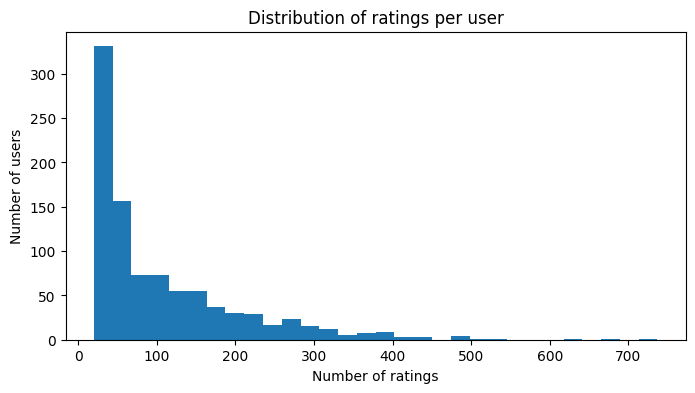

In [18]:
plt.figure(figsize=(8, 4))
plt.hist(ratings_per_usr, bins=30)
plt.xlabel("Number of ratings")
plt.ylabel("Number of users")
plt.title("Distribution of ratings per user")
plt.show()

Strongly rightly skewed

## Movie popularity

Check how many ratings each movie has (number of times a movies id appears = how many ratings)

In [19]:
ratings_per_movie = ratings["movie_id"].value_counts()
ratings_per_movie.describe()

count    1682.000000
mean       59.453032
std        80.383846
min         1.000000
25%         6.000000
50%        27.000000
75%        80.000000
max       583.000000
Name: count, dtype: float64

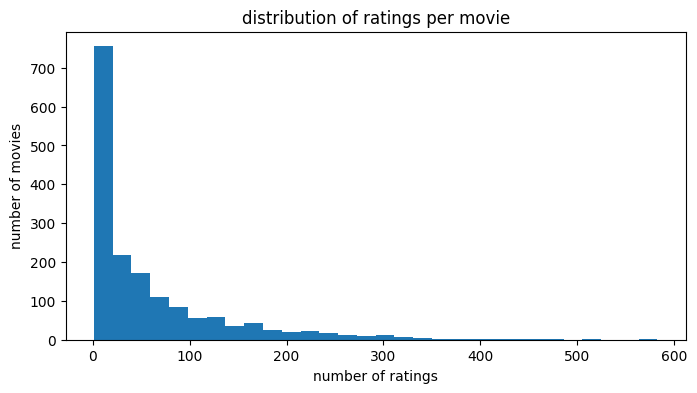

In [20]:
plt.figure(figsize=(8, 4))
plt.hist(ratings_per_movie, bins=30)
plt.xlabel("number of ratings")
plt.ylabel("number of movies")
plt.title("distribution of ratings per movie")
plt.show()

Right skewed again probably because popular movies recieved way more reviews

Counting how many movies in each genre

In [21]:
genre_cnt = movies[genre_names].sum()
genre_cnt = genre_cnt.sort_values(ascending=False)
genre_cnt

Drama          725
Comedy         505
Action         251
Thriller       251
Romance        247
Adventure      135
Children's     122
Crime          109
Sci-Fi         101
Horror          92
War             71
Mystery         61
Musical         56
Documentary     50
Animation       42
Western         27
Film-Noir       24
Fantasy         22
unknown          2
dtype: int64

Visualizing how many movies per genre

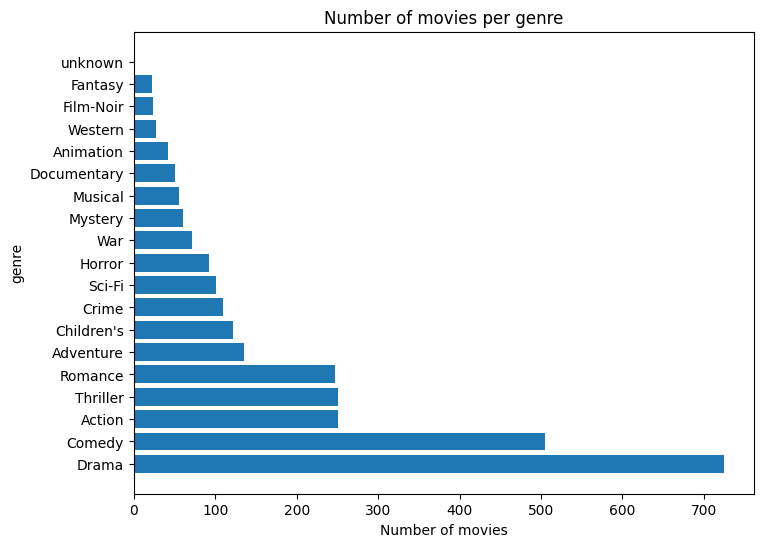

In [24]:
plt.figure(figsize=(8, 6))
plt.barh(genre_cnt.index, genre_cnt.values)
plt.xlabel("Number of movies")
plt.ylabel("genre")
plt.title("Number of movies per genre")
plt.show()

## Summary

MovieLens 100K dataset has 100,000 ratings from 943 users across 1,682 movies.

Ratings range from 1 to 5, with ratings of 3 and 4 being the most common.
User activity is strongly right-skewed, with a small number of users contributing a large number of ratings.
Movie popularity is also strongly right-skewed, with many movies receiving relatively few ratings and a small number receiving several hundred.
genre representation is uneven, with Drama and Comedy being the most common genres.